# Tostao | 02_Feature_Engineering (Diario)

## Objetivo
Construir un dataset diario SKU–Tienda para pronosticar cada uno de los próximos siete días. La salida operativa será una curva de demanda diaria y su acumulado de siete días.

**Corte de inventario:** 2024-03-31.  
**Histórico:** 2024-01-01 a 2024-03-31 (91 días).  
**Granularidad:** fecha × tienda × producto.  
**Horizonte:** siete días futuros.



## 0. Configuración y carga de archivos

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_DIR = Path("/content")  # Cambia si utilizas otra ruta
FILES = {
    "ventas": "ventas_historicas.csv",
    "inventario": "inventario_actual.csv",
    "catalogo": "catalogo_productos.csv",
    "tiendas": "maestro_tiendas.csv",
    "trends": "ground_truth_trends.csv",
}
INVENTORY_CUTOFF = pd.Timestamp("2024-03-31")

def load_csv(filename: str) -> pd.DataFrame:
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"No se encontró {path}. Revisa DATA_DIR y los archivos.")
    return pd.read_csv(path)

ventas = load_csv(FILES["ventas"])
inventario = load_csv(FILES["inventario"])
catalogo = load_csv(FILES["catalogo"])
tiendas = load_csv(FILES["tiendas"])
trends = load_csv(FILES["trends"])

ventas["fecha"] = pd.to_datetime(ventas["fecha"], errors="coerce")
print("Ventas:", ventas.shape)
print("Inventario:", inventario.shape)
print("Catálogo:", catalogo.shape)
print("Tiendas:", tiendas.shape)
print("Ground truth trends:", trends.shape)

Ventas: (14560, 4)
Inventario: (160, 3)
Catálogo: (8, 6)
Tiendas: (20, 3)
Ground truth trends: (160, 3)


## 1. Validación de esquema, fecha y granularidad

In [ ]:
required_sales = {
    "fecha", "id_tienda", "id_producto", "unidades_vendidas"
}
missing = required_sales - set(ventas.columns)
if missing:
    raise ValueError(f"Faltan columnas en ventas: {sorted(missing)}")

if ventas["fecha"].isna().any():
    raise ValueError("Existen fechas inválidas.")
if ventas["unidades_vendidas"].isna().any():
    raise ValueError("Existen unidades vendidas nulas.")
if (ventas["unidades_vendidas"] < 0).any():
    raise ValueError("Hay ventas negativas. Investiga devoluciones/ajustes.")
if ventas.duplicated(["fecha", "id_tienda", "id_producto"]).any():
    raise ValueError("Hay más de un registro por fecha-tienda-producto.")

ventas["unidades_vendidas"] = pd.to_numeric(
    ventas["unidades_vendidas"], errors="raise"
)

print("Periodo:", ventas["fecha"].min(), "a", ventas["fecha"].max())
print("Fechas únicas:", ventas["fecha"].nunique())
print("Combinaciones SKU-Tienda:",
      ventas[["id_tienda", "id_producto"]].drop_duplicates().shape[0])
print("Ventas cero:", int((ventas["unidades_vendidas"] == 0).sum()))

Periodo: 2024-01-01 00:00:00 a 2024-03-31 00:00:00
Fechas únicas: 91
Combinaciones SKU-Tienda: 160
Ventas cero: 26


## 2. Validar cobertura diaria antes de completar el panel

No rellenamos automáticamente fechas ausentes con cero. Primero comprobamos si cada combinación tiene una observación para todos los días del periodo. Solo si la cobertura está completa conservamos los ceros explícitos como observaciones de venta cero.

In [ ]:
date_min = ventas["fecha"].min().normalize()
date_max = ventas["fecha"].max().normalize()
expected_dates = pd.date_range(date_min, date_max, freq="D")

combos = ventas[["id_tienda", "id_producto"]].drop_duplicates()

coverage = (
    ventas.groupby(["id_tienda", "id_producto"])["fecha"]
    .nunique().rename("dias_observados").reset_index()
)
coverage["dias_esperados"] = len(expected_dates)
coverage["cobertura_completa"] = (
    coverage["dias_observados"] == coverage["dias_esperados"]
)

display(coverage["cobertura_completa"].value_counts().to_frame("combinaciones"))
display(coverage.loc[~coverage["cobertura_completa"]].head(20))

if not coverage["cobertura_completa"].all():
    raise ValueError(
        "Hay días sin registro para algunas series. No los imputes como cero "
        "sin confirmar el significado de ausencia en la fuente."
    )

print(f"Cada combinación tiene {len(expected_dates)} observaciones diarias.")

,combinaciones
cobertura_completa,
True,160


,id_tienda,id_producto,dias_observados,dias_esperados,cobertura_completa


Cada combinación tiene 91 observaciones diarias.


## 3. Construir el panel diario completo SKU–Tienda

La llave será `fecha × id_tienda × id_producto`. El panel debe tener una fila por día y combinación observada.

In [ ]:
# Agregación defensiva por llave diaria.
daily_observed = (
    ventas.groupby(
        ["fecha", "id_tienda", "id_producto"], as_index=False
    )
    .agg(demanda=("unidades_vendidas", "sum"))
)

dates = pd.date_range(date_min, date_max, freq="D")
combo_records = combos.sort_values(
    ["id_tienda", "id_producto"]
).to_dict("records")

full_index = pd.MultiIndex.from_product(
    [dates,
     sorted(combos["id_tienda"].unique()),
     sorted(combos["id_producto"].unique())],
    names=["fecha", "id_tienda", "id_producto"]
).to_frame(index=False)

# Conservar únicamente las combinaciones tienda-producto realmente observadas.
full_index = full_index.merge(
    combos, on=["id_tienda", "id_producto"], how="inner"
)

daily = full_index.merge(
    daily_observed,
    on=["fecha", "id_tienda", "id_producto"],
    how="left",
    validate="one_to_one"
)

# La cobertura ya fue verificada; los NaN inesperados serían un problema.
if daily["demanda"].isna().any():
    raise ValueError("Quedaron fechas sin observación después de verificar cobertura.")

daily["demanda"] = daily["demanda"].astype(float)
daily = daily.sort_values(
    ["id_tienda", "id_producto", "fecha"]
).reset_index(drop=True)

expected_rows = len(dates) * len(combos)
print("Filas panel:", len(daily))
print("Filas esperadas:", expected_rows)
print("Combinaciones:", len(combos))
print("Días:", len(dates))

assert len(daily) == expected_rows
assert not daily.duplicated(["fecha", "id_tienda", "id_producto"]).any()

display(daily.head(50))

Filas panel: 14560
Filas esperadas: 14560
Combinaciones: 160
Días: 91


,fecha,id_tienda,id_producto,demanda
0,2024-01-01,STORE_01,PROD_001,5.000
1,2024-01-02,STORE_01,PROD_001,4.000
2,2024-01-03,STORE_01,PROD_001,3.000
3,2024-01-04,STORE_01,PROD_001,4.000
4,2024-01-05,STORE_01,PROD_001,10.000
5,2024-01-06,STORE_01,PROD_001,8.000
6,2024-01-07,STORE_01,PROD_001,8.000
7,2024-01-08,STORE_01,PROD_001,8.000
8,2024-01-09,STORE_01,PROD_001,4.000
9,2024-01-10,STORE_01,PROD_001,3.000


## 4. Variables de calendario: posible estacionalidad semanal

Conservamos el día de semana como categoría y también creamos una representación cíclica. `es_fin_semana` puede ayudar a resumir el efecto de sábado y domingo, pero no reemplaza el día individual.

,mean,median,std,count
dia_semana,,,,
Monday,10.920,10.000,6.016,2080
Tuesday,10.907,10.000,6.116,2080
Wednesday,10.688,10.000,6.203,2080
Thursday,10.806,10.000,6.120,2080
Friday,16.423,15.000,8.681,2080
Saturday,16.179,15.000,8.435,2080
Sunday,16.319,15.000,8.808,2080


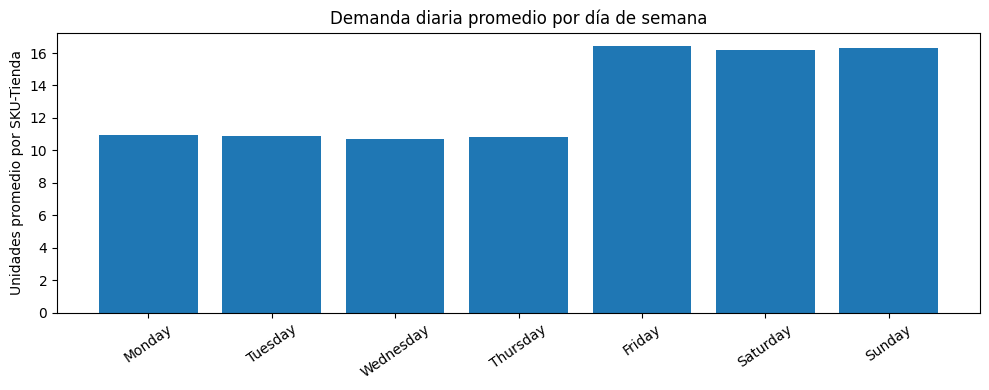

,mean,median,sum,count
Lunes a viernes,11.949,11.000,"124,265.000",10400
Sábado y domingo,16.249,15.000,"67,596.000",4160


In [ ]:
# Monday=0, ..., Sunday=6
daily["dia_semana_num"] = daily["fecha"].dt.dayofweek
daily["dia_semana"] = daily["fecha"].dt.day_name()
daily["es_fin_semana"] = daily["dia_semana_num"].isin([5, 6]).astype(int)

daily["dow_sin"] = np.sin(2 * np.pi * daily["dia_semana_num"] / 7)
daily["dow_cos"] = np.cos(2 * np.pi * daily["dia_semana_num"] / 7)

daily["dia_mes"] = daily["fecha"].dt.day
daily["mes"] = daily["fecha"].dt.month
daily["indice_dia"] = (daily["fecha"] - date_min).dt.days

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
weekday_profile = (
    daily.groupby("dia_semana")["demanda"]
    .agg(["mean", "median", "std", "count"])
    .reindex(weekday_order)
)
display(weekday_profile)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekday_profile.index, weekday_profile["mean"])
ax.set_title("Demanda diaria promedio por día de semana")
ax.set_ylabel("Unidades promedio por SKU-Tienda")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# Comparación agregada entre días hábiles y fin de semana.
weekend_profile = (
    daily.groupby("es_fin_semana")["demanda"]
    .agg(["mean", "median", "sum", "count"])
)
weekend_profile.index = ["Lunes a viernes", "Sábado y domingo"]
display(weekend_profile)

## 5. Indicador de festivo nacional en Colombia

Creamos una única variable:
- `es_festivo`: 1 si la fecha es festivo nacional colombiano; 0 en caso contrario.

El indicador de festivo se mantiene independiente de `es_fin_semana`. El calendario corresponde a festivos nacionales.

In [ ]:
# Instalar dependencia en Google Colab
!pip -q install holidays

import holidays

# Crear calendario de festivos nacionales de Colombia
years_needed = sorted(set(daily["fecha"].dt.year.tolist()))
co_holidays = holidays.country_holidays(
    "CO",
    years=years_needed,
    observed=True
)

# Indicador binario: 1 si es festivo nacional, 0 en caso contrario
holiday_dates = {pd.Timestamp(day) for day in co_holidays.keys()}
daily["es_festivo"] = daily["fecha"].isin(holiday_dates).astype(int)

# Resumen de fechas festivas presentes en el histórico
holiday_calendar = (
    daily.loc[daily["es_festivo"].eq(1), ["fecha"]]
    .drop_duplicates()
    .sort_values("fecha")
)
display(holiday_calendar)

print("Días festivos presentes en el histórico:", len(holiday_calendar))
print("Filas SKU-Tienda marcadas como festivo:", int(daily["es_festivo"].sum()))

display(
    daily.loc[
        daily["es_festivo"].eq(1),
        ["fecha", "dia_semana", "es_fin_semana", "es_festivo"]
    ].drop_duplicates().sort_values("fecha")
)

,fecha
0,2024-01-01
7,2024-01-08
84,2024-03-25
87,2024-03-28
88,2024-03-29


Días festivos presentes en el histórico: 5
Filas SKU-Tienda marcadas como festivo: 800


,fecha,dia_semana,es_fin_semana,es_festivo
0,2024-01-01,Monday,0,1
7,2024-01-08,Monday,0,1
84,2024-03-25,Monday,0,1
87,2024-03-28,Thursday,0,1
88,2024-03-29,Friday,0,1


In [ ]:
# Validaciones del indicador de festivo
assert daily["es_festivo"].isin([0, 1]).all()

# Sábado/domingo y festivo son atributos independientes.
print(pd.crosstab(
    daily["es_fin_semana"],
    daily["es_festivo"],
    rownames=["Fin de semana"],
    colnames=["Festivo"]
))
print("Validación de es_festivo superada.")

Festivo           0    1
Fin de semana           
0              9600  800
1              4160    0
Validación de es_festivo superada.


## 5. Atributos estáticos de producto y tienda

Se agregan para segmentación y para futuros modelos globales. Su inclusión como predictor deberá validarse; por ejemplo, tamaño de tienda puede estar relacionado con la demanda, pero no implica causalidad.

In [ ]:
product_features = catalogo.copy()
product_features["margen_unitario"] = (
    product_features["precio_venta"] - product_features["costo_unitario"]
)
product_features["margen_pct"] = (
    product_features["margen_unitario"] /
    product_features["precio_venta"].replace(0, np.nan)
)

daily = daily.merge(
    product_features[
        ["id_producto", "nombre", "costo_unitario", "precio_venta",
         "costo_almacenamiento_semanal", "margen_unitario", "margen_pct"]
    ],
    on="id_producto", how="left", validate="many_to_one"
)

daily = daily.merge(
    tiendas[["id_tienda", "ciudad", "tamaño_m2"]],
    on="id_tienda", how="left", validate="many_to_one"
)

display(daily.head())

,fecha,id_tienda,id_producto,demanda,dia_semana_num,dia_semana,es_fin_semana,dow_sin,dow_cos,dia_mes,mes,indice_dia,es_festivo,nombre,costo_unitario,precio_venta,costo_almacenamiento_semanal,margen_unitario,margen_pct,ciudad,tamaño_m2
0,2024-01-01,STORE_01,PROD_001,5.000,0,Monday,0,0.000,1.000,1,1,0,1,Tinto,800,2500,10,1700,0.680,Bogotá,28
1,2024-01-02,STORE_01,PROD_001,4.000,1,Tuesday,0,0.782,0.623,2,1,1,0,Tinto,800,2500,10,1700,0.680,Bogotá,28
2,2024-01-03,STORE_01,PROD_001,3.000,2,Wednesday,0,0.975,-0.223,3,1,2,0,Tinto,800,2500,10,1700,0.680,Bogotá,28
3,2024-01-04,STORE_01,PROD_001,4.000,3,Thursday,0,0.434,-0.901,4,1,3,0,Tinto,800,2500,10,1700,0.680,Bogotá,28
4,2024-01-05,STORE_01,PROD_001,10.000,4,Friday,0,-0.434,-0.901,5,1,4,0,Tinto,800,2500,10,1700,0.680,Bogotá,28


## 6. Variables históricas: rezagos y ventanas móviles

Para predecir la demanda del día `t`, las variables deben usar observaciones hasta `t-1`.

- `lag_1`: demanda de ayer.
- `lag_7`: demanda del mismo día de semana anterior.
- `lag_14`: demanda del mismo día hace dos semanas.
- `rolling_mean_7` y `rolling_std_7`: resumen de los siete días previos.
- `rolling_mean_28`: nivel medio de las cuatro semanas previas.
- `rolling_zero_count_7`: número de días con cero ventas en los siete días previos.

La ventana móvil se calcula sobre la serie desplazada, nunca sobre el día objetivo.

In [ ]:
group_cols = ["id_tienda", "id_producto"]
daily = daily.sort_values(group_cols + ["fecha"]).copy()

demand_group = daily.groupby(group_cols, sort=False)["demanda"]

for lag in [1, 7, 14]:
    daily[f"lag_{lag}"] = demand_group.shift(lag)

# Shift de un día para que cada fila solo vea el pasado.
daily["demanda_previa"] = demand_group.shift(1)
rolling = daily.groupby(group_cols, sort=False)["demanda_previa"]

daily["rolling_mean_7"] = rolling.transform(
    lambda s: s.rolling(7, min_periods=7).mean()
)
daily["rolling_std_7"] = rolling.transform(
    lambda s: s.rolling(7, min_periods=7).std()
)
daily["rolling_mean_28"] = rolling.transform(
    lambda s: s.rolling(28, min_periods=28).mean()
)
daily["rolling_sum_7"] = rolling.transform(
    lambda s: s.rolling(7, min_periods=7).sum()
)
daily["rolling_zero_count_7"] = rolling.transform(
    lambda s: s.eq(0).rolling(7, min_periods=7).sum()
)

daily = daily.drop(columns=["demanda_previa"])

lag_features = [
    "lag_1", "lag_7", "lag_14",
    "rolling_mean_7", "rolling_std_7",
    "rolling_mean_28", "rolling_sum_7",
    "rolling_zero_count_7"
]

display(daily[
    ["fecha", "id_tienda", "id_producto", "demanda"] +
    ["dia_semana", "es_fin_semana", "dow_sin", "dow_cos"] +
    lag_features
].head(40))

,fecha,id_tienda,id_producto,demanda,dia_semana,es_fin_semana,dow_sin,dow_cos,lag_1,lag_7,lag_14,rolling_mean_7,rolling_std_7,rolling_mean_28,rolling_sum_7,rolling_zero_count_7
0,2024-01-01,STORE_01,PROD_001,5.000,Monday,0,0.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-02,STORE_01,PROD_001,4.000,Tuesday,0,0.782,0.623,5.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-01-03,STORE_01,PROD_001,3.000,Wednesday,0,0.975,-0.223,4.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-04,STORE_01,PROD_001,4.000,Thursday,0,0.434,-0.901,3.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-01-05,STORE_01,PROD_001,10.000,Friday,0,-0.434,-0.901,4.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2024-01-06,STORE_01,PROD_001,8.000,Saturday,1,-0.975,-0.223,10.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2024-01-07,STORE_01,PROD_001,8.000,Sunday,1,-0.782,0.623,8.000,NaN,NaN,NaN,NaN,NaN,NaN,0.000
7,2024-01-08,STORE_01,PROD_001,8.000,Monday,0,0.000,1.000,8.000,5.000,NaN,6.000,2.646,NaN,42.000,0.000
8,2024-01-09,STORE_01,PROD_001,4.000,Tuesday,0,0.782,0.623,8.000,4.000,NaN,6.429,2.699,NaN,45.000,0.000
9,2024-01-10,STORE_01,PROD_001,3.000,Wednesday,0,0.975,-0.223,4.000,3.000,NaN,6.429,2.699,NaN,45.000,0.000


## 7. Dataset supervisado diario

La variable objetivo es la demanda del propio día (`demanda`). Las variables predictoras de esa fila contienen únicamente información disponible antes de ese día, además del calendario conocido del día objetivo.

Las primeras 28 observaciones de cada combinación no tienen `rolling_mean_28`; por eso no entran en el dataset supervisado principal. Se conserva el panel original completo para análisis.

In [ ]:
calendar_features = [
    "dia_semana_num", "es_fin_semana", "dow_sin", "dow_cos",
    "dia_mes", "mes", "indice_dia", "es_festivo"
]
static_features = [
    "id_tienda", "id_producto", "ciudad", "tamaño_m2"
]

feature_cols = lag_features + calendar_features + static_features

model_data = daily.dropna(subset=lag_features).copy()

print("Panel diario completo:", len(daily))
print("Dataset supervisado:", len(model_data))
print("Series:", model_data[group_cols].drop_duplicates().shape[0])
print("Fechas utilizables:", model_data["fecha"].nunique())
print("Variables predictoras:", len(feature_cols))

assert model_data[feature_cols].notna().all().all()
display(model_data[["fecha", "id_tienda", "id_producto", "demanda"] + feature_cols].head())

Panel diario completo: 14560
Dataset supervisado: 10080
Series: 160
Fechas utilizables: 63
Variables predictoras: 20


,fecha,id_tienda,id_producto,demanda,lag_1,lag_7,lag_14,rolling_mean_7,rolling_std_7,rolling_mean_28,rolling_sum_7,rolling_zero_count_7,dia_semana_num,es_fin_semana,dow_sin,dow_cos,dia_mes,mes,indice_dia,es_festivo,id_tienda,id_producto,ciudad,tamaño_m2
28,2024-01-29,STORE_01,PROD_001,8.000,8.000,5.000,5.000,8.143,5.490,6.821,57.000,0.000,0,0,0.000,1.000,29,1,28,0,STORE_01,PROD_001,Bogotá,28
29,2024-01-30,STORE_01,PROD_001,5.000,8.000,5.000,2.000,8.571,5.318,6.929,60.000,0.000,1,0,0.782,0.623,30,1,29,0,STORE_01,PROD_001,Bogotá,28
30,2024-01-31,STORE_01,PROD_001,8.000,5.000,9.000,7.000,8.571,5.318,6.964,60.000,0.000,2,0,0.975,-0.223,31,1,30,0,STORE_01,PROD_001,Bogotá,28
31,2024-02-01,STORE_01,PROD_001,3.000,8.000,5.000,7.000,8.429,5.318,7.143,59.000,0.000,3,0,0.434,-0.901,1,2,31,0,STORE_01,PROD_001,Bogotá,28
32,2024-02-02,STORE_01,PROD_001,8.000,3.000,20.000,5.000,8.143,5.581,7.107,57.000,0.000,4,0,-0.434,-0.901,2,2,32,0,STORE_01,PROD_001,Bogotá,28


## 8. Pruebas anti-leakage

Comprobamos que `lag_1`, `lag_7` y las medias móviles correspondan exactamente a fechas anteriores dentro de cada SKU–Tienda.

In [ ]:
check = daily.sort_values(group_cols + ["fecha"]).copy()
grp = check.groupby(group_cols, sort=False)["demanda"]

expected_lag1 = grp.shift(1)
expected_lag7 = grp.shift(7)
expected_lag14 = grp.shift(14)

assert np.allclose(
    check.loc[expected_lag1.notna(), "lag_1"],
    expected_lag1.loc[expected_lag1.notna()]
)
assert np.allclose(
    check.loc[expected_lag7.notna(), "lag_7"],
    expected_lag7.loc[expected_lag7.notna()]
)
assert np.allclose(
    check.loc[expected_lag14.notna(), "lag_14"],
    expected_lag14.loc[expected_lag14.notna()]
)

# rolling_mean_7 debe ser la media de los siete valores previos.
expected_rm7 = grp.transform(
    lambda s: s.shift(1).rolling(7, min_periods=7).mean()
)
valid = expected_rm7.notna()
assert np.allclose(
    check.loc[valid, "rolling_mean_7"],
    expected_rm7.loc[valid]
)

print("OK: rezagos y ventanas móviles usan únicamente datos pasados.")

OK: rezagos y ventanas móviles usan únicamente datos pasados.


## 9. Diseño de evaluación temporal para horizonte de siete días

El horizonte operativo es una semana completa. Para evaluar una decisión tomada en una fecha de corte, el pronóstico de los siete días siguientes no puede usar ventas reales de los primeros días de esa misma semana.

En el notebook de forecasting implementaremos backtesting por bloques de siete días. Cada fold tendrá:
- Fecha de origen/corte.
- Historial disponible hasta el corte.
- Pronóstico de los siguientes siete días.
- Comparación con las ventas observadas en esos siete días.

Para un modelo recursivo, los rezagos futuros se actualizarán con predicciones, no con ventas reales de los días intermedios. Para un modelo directo, se construirán ejemplos por horizonte 1 a 7.

La tabla siguiente define tres bloques semanales al final del histórico. El entrenamiento y la simulación se implementarán en el notebook 03.

In [ ]:
all_dates = pd.date_range(date_min, date_max, freq="D")
# Tres bloques de validación, cada uno de siete días.
validation_starts = [all_dates[-21], all_dates[-14], all_dates[-7]]

fold_rows = []
for start in validation_starts:
    end = start + pd.Timedelta(days=6)
    origin = start - pd.Timedelta(days=1)
    fold_rows.append({
        "origin_date": origin,
        "validation_start": start,
        "validation_end": end,
        "history_days_available": int((origin - date_min).days + 1),
        "validation_horizon_days": 7
    })

fold_plan = pd.DataFrame(fold_rows)
display(fold_plan)

assert (fold_plan["validation_end"] <= date_max).all()
assert (fold_plan["validation_start"] > fold_plan["origin_date"]).all()

,origin_date,validation_start,validation_end,history_days_available,validation_horizon_days
0,2024-03-10,2024-03-11,2024-03-17,70,7
1,2024-03-17,2024-03-18,2024-03-24,77,7
2,2024-03-24,2024-03-25,2024-03-31,84,7


## 10. Baseline estacional que evaluaremos en forecasting

También compararemos:
- Naive: último valor observado.
- Media móvil: promedio reciente.
- Seasonal Naive (7 días): mismo día de la semana anterior.

No declaramos ganadora ninguna metodología hasta ejecutar backtesting y medir error y sesgo por horizonte, producto y tienda.

In [ ]:
# Ejemplo de construcción de predicción Seasonal Naive para un corte.
# Esta función se utilizará en forecasting y devuelve el valor de hace 7 días
# para cada fecha futura, usando únicamente el historial disponible al corte.

def seasonal_naive_7day(
    history: pd.DataFrame,
    origin_date: pd.Timestamp,
    horizon: int = 7
) -> pd.DataFrame:
    required = {"fecha", "id_tienda", "id_producto", "demanda"}
    missing = required - set(history.columns)
    if missing:
        raise ValueError(f"Faltan columnas: {sorted(missing)}")

    hist = history.loc[history["fecha"] <= origin_date].copy()
    future_dates = pd.date_range(
        origin_date + pd.Timedelta(days=1),
        periods=horizon,
        freq="D"
    )

    rows = []
    for (store, sku), series in hist.groupby(["id_tienda", "id_producto"]):
        lookup = series.set_index("fecha")["demanda"]
        for target_date in future_dates:
            reference_date = target_date - pd.Timedelta(days=7)
            pred = lookup.get(reference_date, np.nan)
            rows.append({
                "id_tienda": store,
                "id_producto": sku,
                "fecha_objetivo": target_date,
                "fecha_referencia": reference_date,
                "pred_seasonal_naive_7": pred
            })

    return pd.DataFrame(rows)

# Prueba de ejemplo en el último corte de validación.
example_origin = pd.Timestamp(validation_starts[-1]) - pd.Timedelta(days=1)
example_pred = seasonal_naive_7day(
    daily[["fecha", "id_tienda", "id_producto", "demanda"]],
    example_origin,
    horizon=7
)
display(example_pred.head(14))
print("Predicciones faltantes por referencia histórica:",
      int(example_pred["pred_seasonal_naive_7"].isna().sum()))

,id_tienda,id_producto,fecha_objetivo,fecha_referencia,pred_seasonal_naive_7
0,STORE_01,PROD_001,2024-03-25,2024-03-18,3.000
1,STORE_01,PROD_001,2024-03-26,2024-03-19,6.000
2,STORE_01,PROD_001,2024-03-27,2024-03-20,7.000
3,STORE_01,PROD_001,2024-03-28,2024-03-21,3.000
4,STORE_01,PROD_001,2024-03-29,2024-03-22,5.000
5,STORE_01,PROD_001,2024-03-30,2024-03-23,10.000
6,STORE_01,PROD_001,2024-03-31,2024-03-24,11.000
7,STORE_01,PROD_002,2024-03-25,2024-03-18,7.000
8,STORE_01,PROD_002,2024-03-26,2024-03-19,11.000
9,STORE_01,PROD_002,2024-03-27,2024-03-20,6.000


Predicciones faltantes por referencia histórica: 0


## 12. Exportar panel y dataset de características

In [ ]:
OUTPUT_DIR = Path("/content/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

panel_path = OUTPUT_DIR / "panel_diario_sku_tienda.csv"
features_path = OUTPUT_DIR / "dataset_features_diario.csv"
folds_path = OUTPUT_DIR / "backtesting_plan_7day.csv"

daily.to_csv(panel_path, index=False)
model_data.to_csv(features_path, index=False)
fold_plan.to_csv(folds_path, index=False)

print("Exportados:")
print(panel_path)
print(features_path)
print(folds_path)

try:
    from google.colab import files
    files.download(str(features_path))
except ImportError:
    print("Ejecutando fuera de Colab: revisa OUTPUT_DIR.")

Exportados:
/content/processed/panel_diario_sku_tienda.csv
/content/processed/dataset_features_diario.csv
/content/processed/backtesting_plan_7day.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>